In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.feature_selection import SelectFromModel

In [2]:
X_dev = pd.read_csv('X_dev.csv')
y_dev = pd.read_csv('y_dev.csv')

X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.3, random_state=42)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_val = le.transform(y_val)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_val = sc.transform(X_val)

X_train = pd.DataFrame(X_train, columns=X_dev.columns)

c:\programowanie\sem6\ML_mini\.venv\lib\site-packages\sklearn\preprocessing\_label.py:114: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\programowanie\sem6\ML_mini\.venv\lib\site-packages\sklearn\preprocessing\_label.py:132: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


In [3]:
X_train = X_train[['u','redshift', 'g', 'z']]

In [4]:
X_val = pd.DataFrame(X_val, columns=X_dev.columns)
X_val = X_val[['u','redshift', 'g', 'z']]

# Final feature selection

In [6]:
# sprawdzenie jak usuniecie zmiennych zmieni predykcyjnosc

# Model selection

## Trying different models

In [7]:
def get_models():
    
    models = dict()
    models['lr'] = LogisticRegression()
    # models['svm'] = SVC()
    models['gbc'] = GradientBoostingClassifier()
    models['dt'] = DecisionTreeClassifier()
    models['rf'] = RandomForestClassifier()
    models['knn'] = KNeighborsClassifier()
    models['nb'] = GaussianNB()
    models['ada'] = AdaBoostClassifier()
    models['bag'] = BaggingClassifier()

    return models

In [5]:
def evaluate_model(model, X, y):
    
    cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=1)
    scores = cross_val_score(model, X, y, scoring='accuracy', cv=cv, n_jobs=-1, error_score='raise')

    return scores

In [8]:
# modele do evaluacji
models = get_models()
# ocena modeli
results, names = list(), list()
for name, model in models.items():
    scores = evaluate_model(model, X_train, y_train)
    results.append(scores)
    names.append(name)
    print('%8s mean-%.3f std-%.3f' % (name, np.mean(scores), np.std(scores)))

NameError: name 'evaluate_model' is not defined

## svc
can't converge??

In [14]:
clf = make_pipeline(StandardScaler(), SVC(C=1, kernel='rbf', probability=True, tol=1e-3, max_iter=500, random_state=42))
clf.fit(X_train, y_train)
y_pred = clf.predict(X_val)

print(accuracy_score(y_val, y_pred))

c:\programowanie\sem6\ML_mini\.venv\lib\site-packages\sklearn\svm\_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
c:\programowanie\sem6\ML_mini\.venv\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


0.7520476190476191


## random search on decision tree

In [ ]:
param_grid = {
    # 'n_estimators': [100, 200, 300, 400, 500],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    # 'bootstrap': [True, False]
}

# rf = RandomForestClassifier()
estimate = DecisionTreeClassifier()
tree_random = RandomizedSearchCV(estimator = estimate, param_distributions = param_grid, n_iter = 10, cv = 3, verbose=3, random_state=42, n_jobs = -1)
tree_random.fit(X_train, y_train)
print(tree_random.best_params_)

tree_random.best_estimator_.fit(X_train, y_train)
y_pred = tree_random.best_estimator_.predict(X_val)
print(accuracy_score(y_val, y_pred))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
{'min_samples_split': 10, 'min_samples_leaf': 4, 'max_depth': 10}
0.9726190476190476


## Stacking

In [22]:
estimators = [
('tree', DecisionTreeClassifier(max_depth=10, min_samples_leaf=2, min_samples_split=5)),
# ('svc', SVC(C=1, kernel='linear', probability=True)),
# ('rf', RandomForestClassifier(n_estimators=100, min_samples_split=2, min_samples_leaf=4, max_depth=10, bootstrap=True)),
('knn', KNeighborsClassifier(n_neighbors=5)),
('nb', GaussianNB()),
('lr', LogisticRegression())
]

clf = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(), n_jobs=-1)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_val)
print(accuracy_score(y_val, y_pred))

0.9763809523809523


## Gradient boosting

In [8]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_val)
print(accuracy_score(y_val, y_pred))

0.9775238095238096


In [19]:
sfm = SelectFromModel(DecisionTreeClassifier(random_state=42), threshold=0.005)

sfm.fit(X_train, y_train)
X_train = sfm.transform(X_train)
X_val = sfm.transform(X_val)

gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_val)
print(accuracy_score(y_val, y_pred))

0.9761428571428571


### random search

In [9]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'learning_rate': [0.1, 0.2],
}

gb = GradientBoostingClassifier()
gb_random = RandomizedSearchCV(estimator = gb, param_distributions = param_grid, n_iter = 10, cv = 3, verbose=2, random_state=42, n_jobs = -1)
gb_random.fit(X_train, y_train)

print(gb_random.best_params_)
gb_random.cv_results_

Fitting 3 folds for each of 10 candidates, totalling 30 fits


KeyboardInterrupt: 

# Report / more metrics

              precision    recall  f1-score   support

           0      0.975     0.987     0.981     12538
           1      0.962     0.922     0.942      3973
           2      0.996     0.999     0.998      4489

    accuracy                          0.978     21000
   macro avg      0.978     0.970     0.974     21000
weighted avg      0.977     0.978     0.977     21000



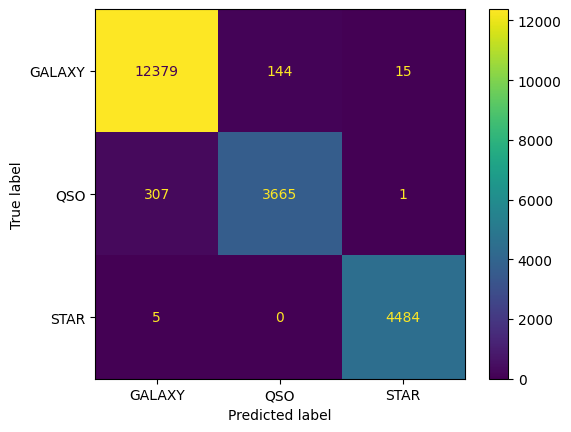

In [ ]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
y_pred = gb.predict(X_val)
print(classification_report(y_val, y_pred, digits=3))
cm = confusion_matrix(y_val, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot()

## Shapley

In [19]:
import shap

model = LogisticRegression()
model.fit(X_train, y_train)

# tree_model = RandomForestClassifier(n_estimators=259, max_depth=13, criterion='entropy', max_features='log2', class_weight=None)
# tree_model.fit(X_train, y_train)

# fig, ax = shap.partial_dependence_plot('redshift', model.predict, X_train, model_expected_value=True,
#                                         feature_expected_value=True, ice=False, show=False)


LogisticRegression()

In [6]:
y_pred = tree_model.predict(X_val)
print(accuracy_score(y_val, y_pred))

0.9773333333333334


In [20]:
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_train)

# explainer = shap.Explainer(tree_model, X_train)
# explainer = shap.TreeExplainer(tree_model)
# shap_values = explainer(X_train)

In [12]:
print(shap_values.shape,"= (n_samples, n_features, n_classes)")
print(X_train.columns)
print(tree_model.classes_)
print(le.classes_)

(49000, 4, 3) = (n_samples, n_features, n_classes)
Index(['u', 'redshift', 'g', 'z'], dtype='object')
[0 1 2]
['GALAXY' 'QSO' 'STAR']


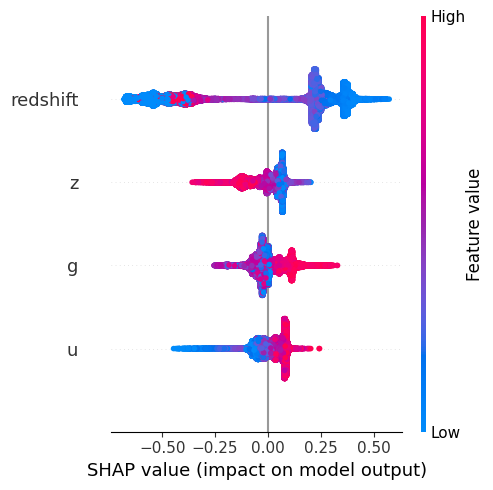

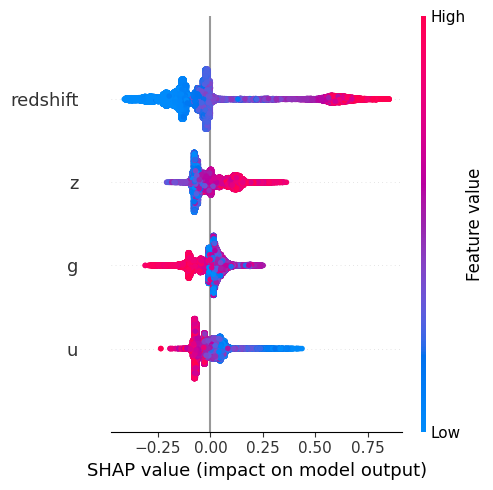

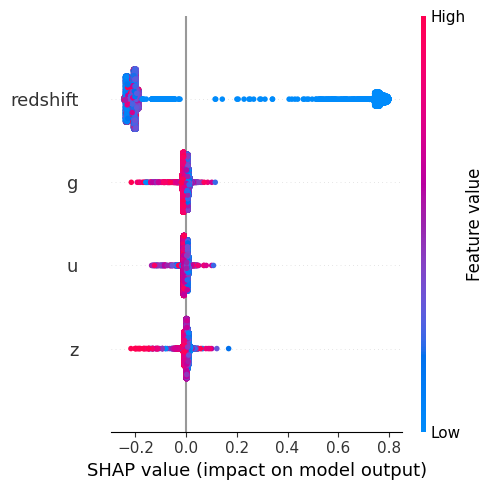

In [9]:
shap.summary_plot(shap_values[:,:,0], plot_size=(5, 5))
shap.summary_plot(shap_values[:,:,1], plot_size=(5, 5))
shap.summary_plot(shap_values[:,:,2], plot_size=(5, 5))

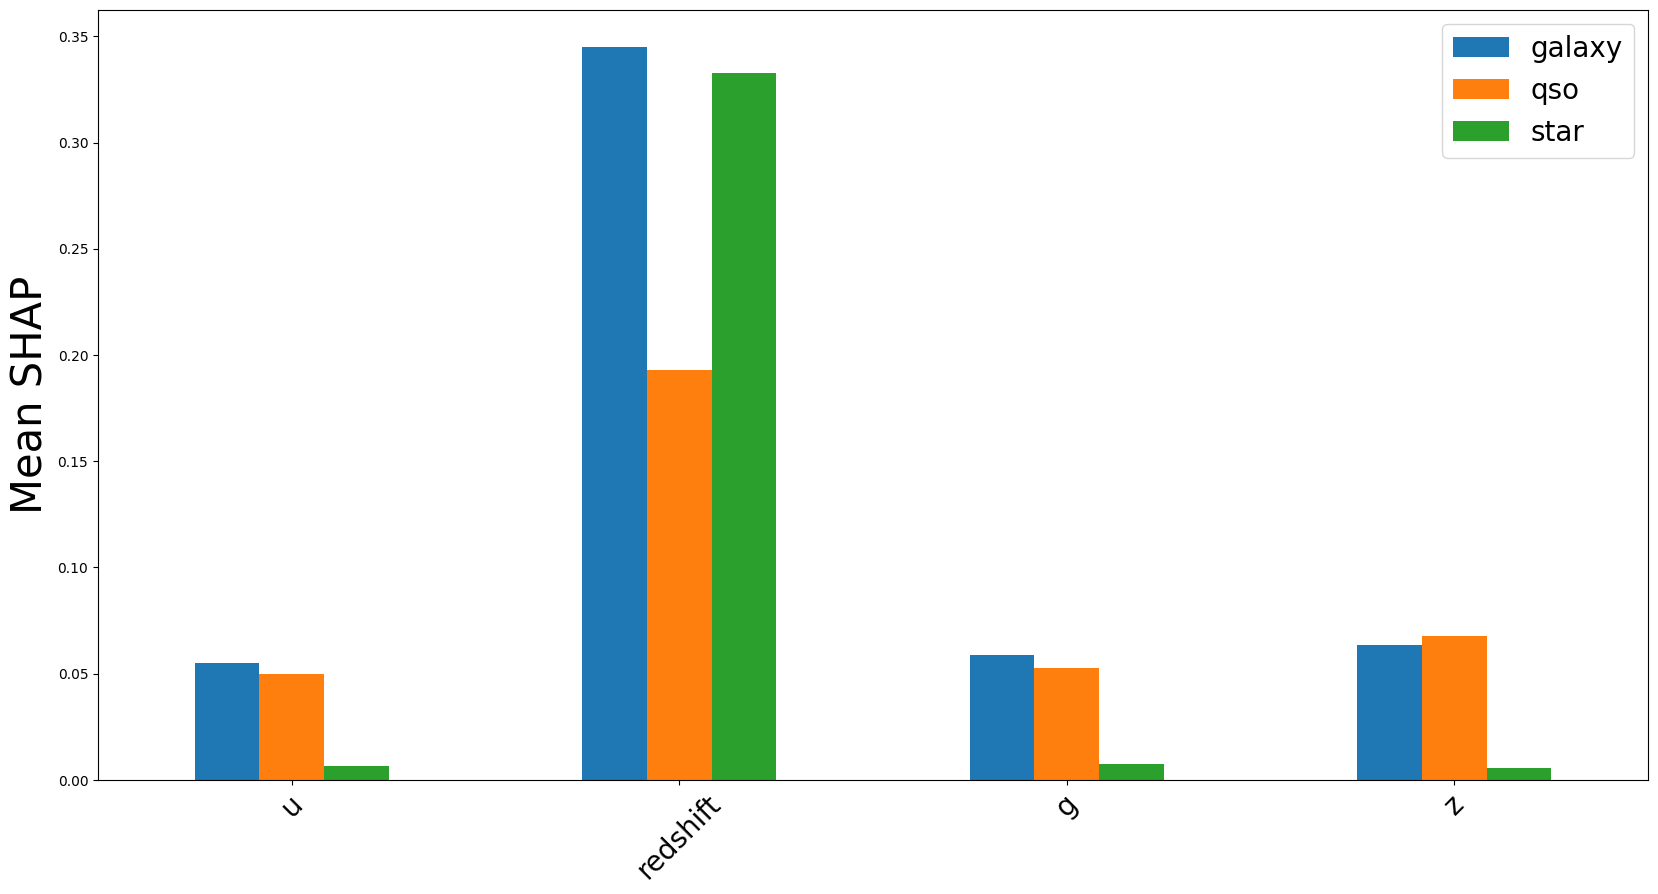

In [10]:
# calculate mean SHAP values for each class
mean_0 = np.mean(np.abs(shap_values.values[:,:,0]),axis=0)
mean_1 = np.mean(np.abs(shap_values.values[:,:,1]),axis=0)
mean_2 = np.mean(np.abs(shap_values.values[:,:,2]),axis=0)

df = pd.DataFrame({'galaxy':mean_0,'qso':mean_1,'star':mean_2})

# plot mean SHAP values
fig,ax = plt.subplots(1,1,figsize=(20,10))
df.plot.bar(ax=ax)

ax.set_ylabel('Mean SHAP',size = 30)
ax.set_xticklabels(X_train.columns,rotation=45,size=20)
ax.legend(fontsize=20)
# mean abs shap dla każdej klasy - określa jakie zmienne są najważniejsze dla każdej klasy

In [13]:
# get model predictions
preds = tree_model.predict(X_train)

new_shap_values = []
for i, pred in enumerate(preds):
    # get shap values for predicted class
    new_shap_values.append(shap_values.values[i][:,pred])

shap_values.values = np.array(new_shap_values)
print(shap_values.shape)
# tworzymy nowy obiekt shap_values, który zawiera tylko wartości SHAP dla przewidzianych klas,
# teraz możemy zobaczyć jakie zmienne wpływają predykcje modelu

(49000, 4)


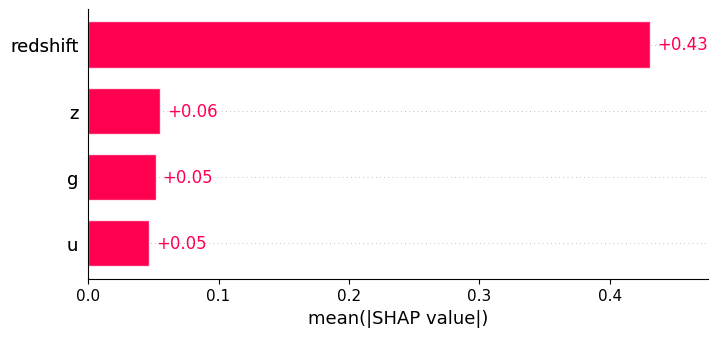

In [14]:
shap.plots.bar(shap_values)

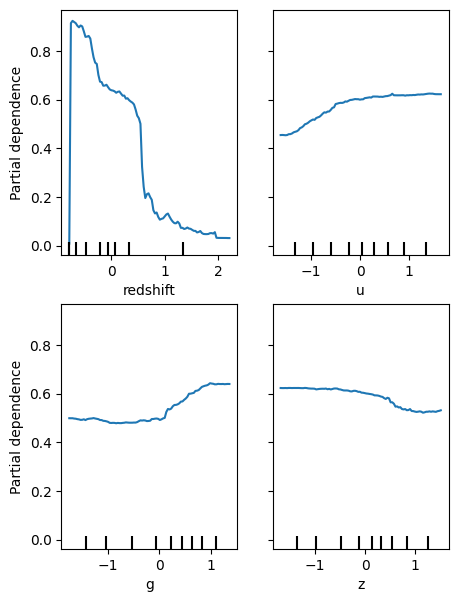

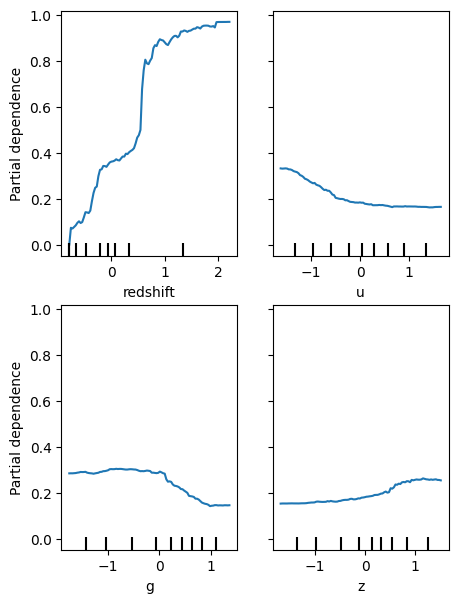

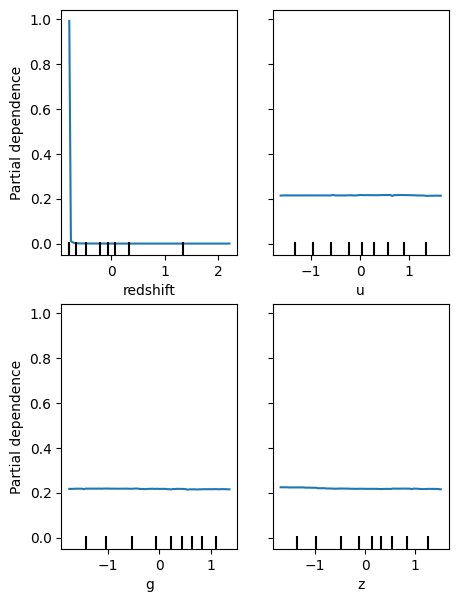

In [29]:
from sklearn.inspection import PartialDependenceDisplay

features = ['redshift', 'u', 'g', 'z']
fig, ax = plt.subplots(figsize=(5, 7))
PartialDependenceDisplay.from_estimator(tree_model, X_train, features, target=0, n_cols=2, ax=ax)
fig, ax = plt.subplots(figsize=(5, 7))
PartialDependenceDisplay.from_estimator(tree_model, X_train, features, target=1, n_cols=2, ax=ax)
fig, ax = plt.subplots(figsize=(5, 7))
PartialDependenceDisplay.from_estimator(tree_model, X_train, features, target=2, n_cols=2, ax=ax)